<a href="https://colab.research.google.com/github/Tarang06go/UCS420/blob/main/Assignment10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Configuration and required libraries
# Change ONLY this field to match your roll number: "odd" or "even".
ROLL_PARITY = "odd"
assert ROLL_PARITY in ("odd", "even"), "Select 'odd' or 'even'."

import sys, subprocess, importlib.util
for package, module in [("pandas", "pandas"), ("scikit-learn", "sklearn"),
                        ("matplotlib", "matplotlib"), ("seaborn", "seaborn"),
                        ("nltk", "nltk"), ("ipywidgets", "ipywidgets")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", package])

import re, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from IPython.display import display, Markdown, clear_output
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import ipywidgets as widgets
from nltk.stem import WordNetLemmatizer
nltk.download("wordnet", quiet=True)

DOMAIN = "diabetes" if ROLL_PARITY == "odd" else "heart"
print("Selected assistant:", "Diabetes Care" if DOMAIN == "diabetes" else "Heart Health")

Selected assistant: Diabetes Care


## 2. Hierarchical taxonomy (4 main categories × 2 subcategories)
Every subcategory below is also an **intent**. This gives **8 intent classes** (more than 5 required).

In [2]:
TAXONOMY = {
    "Understanding the condition": ["basics", "symptoms"],
    "Prevention and daily care": ["diet", "exercise"],
    "Clinical care": ["testing", "treatment"],
    "Long-term wellbeing": ["risk_factors", "complications"],
}
for major, subcategories in TAXONOMY.items():
    print(major, "->", ", ".join(subcategories))
assert len(TAXONOMY) >= 4 and all(len(v)>=2 for v in TAXONOMY.values())

Understanding the condition -> basics, symptoms
Prevention and daily care -> diet, exercise
Clinical care -> testing, treatment
Long-term wellbeing -> risk_factors, complications


## 3. Labelled query corpus
Each assistant includes **64 labelled queries** (8 intents × 8 example queries), with an independent stratified test split. Data are educational examples created for this assignment, not clinical records.

In [3]:
DATA = {
"diabetes": {
"basics": [
 "What is diabetes?", "Explain diabetes in simple words", "What happens in diabetes?", "What is high blood sugar?",
 "How does insulin affect glucose?", "Tell me about type 1 and type 2 diabetes", "What does diabetes mellitus mean?", "Why is blood glucose important?"],
"symptoms": [
 "What are the symptoms of diabetes?", "Why am I always thirsty with diabetes?", "Can frequent urination be a sign of diabetes?", "What are early signs of high blood sugar?",
 "Does diabetes cause tiredness?", "Why might blurry vision occur in diabetes?", "What warning signs suggest diabetes?", "Can unexplained weight loss be a diabetes symptom?"],
"diet": [
 "What diet is helpful for diabetes?", "Which foods are useful for blood sugar management?", "Should people with diabetes limit sugary drinks?", "How do carbohydrates affect glucose?",
 "Can I eat fruit if I have diabetes?", "What is a balanced diabetes meal?", "How can meal portions help blood sugar?", "What should I know about fiber in a diabetes diet?"],
"exercise": [
 "Is walking beneficial for diabetes?", "How does exercise affect glucose?", "Can I do strength training with diabetes?", "What physical activity is recommended for diabetes?",
 "Why is regular movement helpful for blood sugar?", "How should I start exercising with diabetes?", "What precautions are needed for diabetes workouts?", "Can cycling support diabetes management?"],
"testing": [
 "How is diabetes diagnosed?", "What does an HbA1c test measure?", "What is fasting blood glucose?", "When should glucose levels be checked?",
 "What is an oral glucose tolerance test?", "How are blood sugar readings monitored?", "What do glucose test results mean?", "How is a continuous glucose monitor used?"],
"treatment": [
 "How is diabetes treated?", "Why is insulin prescribed for diabetes?", "What medicines are used for type 2 diabetes?", "Can lifestyle changes help manage diabetes?",
 "How do people plan diabetes treatment with a doctor?", "What is the role of metformin in diabetes care?", "Is insulin needed for type 1 diabetes?", "How is diabetes management adjusted over time?"],
"risk_factors": [
 "What increases the risk of type 2 diabetes?", "Is family history linked to diabetes?", "Does inactivity raise diabetes risk?", "How can I lower my chances of developing diabetes?",
 "What is prediabetes?", "Can age affect diabetes risk?", "How does body weight relate to type 2 diabetes risk?", "What are common diabetes risk factors?"],
"complications": [
 "What complications can diabetes cause?", "How can diabetes affect the kidneys?", "Does diabetes damage nerves?", "Why are foot checks important in diabetes?",
 "Can diabetes affect eye health?", "What is diabetic neuropathy?", "How is heart health connected to diabetes?", "What long-term problems can uncontrolled blood sugar cause?"]
},
"heart": {
"basics": [
 "What is heart health?", "Explain the role of the heart", "What is cardiovascular disease?", "What do arteries do?",
 "What is coronary artery disease?", "How does the heart pump blood?", "What is a healthy cardiovascular system?", "Why is circulation important for the heart?"],
"symptoms": [
 "What are symptoms of heart problems?", "What warning signs can occur with heart disease?", "Can shortness of breath be a heart symptom?", "What does chest discomfort mean?",
 "Can heart conditions cause unusual fatigue?", "What are possible symptoms of angina?", "Why might ankles swell with heart failure?", "What symptoms should prompt heart evaluation?"],
"diet": [
 "What diet supports heart health?", "Are vegetables good for the heart?", "How can limiting salt help the heart?", "What is a heart healthy eating pattern?",
 "Should saturated fats be limited for heart health?", "How does dietary fiber affect cholesterol?", "What foods may support cardiovascular health?", "Is the Mediterranean eating pattern heart friendly?"],
"exercise": [
 "Does walking improve heart health?", "How much activity supports cardiovascular fitness?", "Is cycling good for the heart?", "Why is regular exercise important for circulation?",
 "Can aerobic exercise help heart health?", "What are safe ways to begin heart exercise?", "Can strength training benefit the cardiovascular system?", "How can I be more active for heart health?"],
"testing": [
 "What tests check heart health?", "What does an ECG test show?", "Why measure blood pressure?", "What is a cholesterol blood test?",
 "What is an echocardiogram?", "How is heart disease evaluated?", "When is a cardiac stress test considered?", "How do doctors check cardiovascular risk?"],
"treatment": [
 "How is heart disease treated?", "What treatments are used for high blood pressure?", "Why might statins be prescribed?", "Can lifestyle changes help cardiovascular disease?",
 "When is a stent used?", "How do doctors decide on heart medications?", "What is cardiac rehabilitation?", "How is coronary artery disease managed?"],
"risk_factors": [
 "What factors increase heart disease risk?", "Is smoking bad for the heart?", "How does high blood pressure affect heart risk?", "Does family history increase cardiovascular risk?",
 "How does high LDL cholesterol affect arteries?", "Can diabetes raise heart disease risk?", "How does inactivity influence cardiac risk?", "What are modifiable heart disease risk factors?"],
"complications": [
 "What are complications of cardiovascular disease?", "What is heart failure?", "Can heart disease lead to stroke?", "What is a heart attack?",
 "How can blocked arteries affect the heart?", "What problems arise from untreated high blood pressure?", "What is an irregular heart rhythm?", "What long term effects can heart disease cause?"]
}}
rows = [(query, intent) for intent, queries in DATA[DOMAIN].items() for query in queries]
df = pd.DataFrame(rows, columns=["query", "intent"])
print(f"Total labelled queries: {len(df)}; distinct intents: {df.intent.nunique()}")
display(df.groupby("intent").size().rename("count").to_frame())
display(df.head(8))
assert len(df)>=40 and df.intent.nunique()>=5

Total labelled queries: 64; distinct intents: 8


,count
intent,
basics,8
complications,8
diet,8
exercise,8
risk_factors,8
symptoms,8
testing,8
treatment,8


,query,intent
0,What is diabetes?,basics
1,Explain diabetes in simple words,basics
2,What happens in diabetes?,basics
3,What is high blood sugar?,basics
4,How does insulin affect glucose?,basics
5,Tell me about type 1 and type 2 diabetes,basics
6,What does diabetes mellitus mean?,basics
7,Why is blood glucose important?,basics


## 4. Domain concepts and semantic relationships
The knowledge graph contains **at least 8 concepts** and **at least 10 directed relationships**. Displayed as a relationship table for inspection.

In [4]:
CONCEPTS = {
"diabetes": ["Diabetes", "Insulin", "Glucose", "Pancreas", "HbA1c", "Diet", "Physical activity", "Kidneys", "Eyes", "Nerves", "Prediabetes", "Medication"],
"heart": ["Heart", "Arteries", "Blood pressure", "LDL cholesterol", "Plaque", "Exercise", "Diet", "Smoking", "ECG", "Heart attack", "Stroke", "Medication"]}
RELATIONS = {
"diabetes": [
 ("Pancreas", "produces", "Insulin"), ("Insulin", "helps regulate", "Glucose"),
 ("Diabetes", "involves elevated", "Glucose"), ("HbA1c", "reflects average", "Glucose"),
 ("Diet", "influences", "Glucose"), ("Physical activity", "influences", "Glucose"),
 ("Diabetes", "can affect", "Kidneys"), ("Diabetes", "can affect", "Eyes"),
 ("Diabetes", "can affect", "Nerves"), ("Prediabetes", "increases risk of", "Diabetes"),
 ("Medication", "can help manage", "Diabetes"), ("Physical activity", "supports management of", "Diabetes")],
"heart": [
 ("Heart", "pumps blood through", "Arteries"), ("Blood pressure", "affects health of", "Arteries"),
 ("LDL cholesterol", "can contribute to", "Plaque"), ("Plaque", "can narrow", "Arteries"),
 ("Smoking", "damages", "Arteries"), ("Exercise", "supports", "Heart"),
 ("Diet", "can influence", "LDL cholesterol"), ("ECG", "records electrical activity of", "Heart"),
 ("Plaque", "can contribute to", "Heart attack"), ("Blood pressure", "when elevated increases risk of", "Stroke"),
 ("Medication", "can help manage", "Blood pressure"), ("Diet", "supports health of", "Heart")]
}
relation_df = pd.DataFrame(RELATIONS[DOMAIN], columns=["source concept", "relationship", "target concept"])
print("Concepts:", ", ".join(CONCEPTS[DOMAIN]))
display(relation_df)
assert len(CONCEPTS[DOMAIN])>=8 and len(RELATIONS[DOMAIN])>=10

Concepts: Diabetes, Insulin, Glucose, Pancreas, HbA1c, Diet, Physical activity, Kidneys, Eyes, Nerves, Prediabetes, Medication


,source concept,relationship,target concept
0,Pancreas,produces,Insulin
1,Insulin,helps regulate,Glucose
2,Diabetes,involves elevated,Glucose
3,HbA1c,reflects average,Glucose
4,Diet,influences,Glucose
5,Physical activity,influences,Glucose
6,Diabetes,can affect,Kidneys
7,Diabetes,can affect,Eyes
8,Diabetes,can affect,Nerves
9,Prediabetes,increases risk of,Diabetes


## 5. NLP preprocessing — lowercasing, tokenization, stopword removal, lemmatization



In [5]:
lemmatizer = WordNetLemmatizer()
STOPWORDS = set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "without"}
def preprocess(text):
    text = str(text).lower()                         # lowercase
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text) # tokenize
    filtered = [t for t in tokens if t not in STOPWORDS]  # remove stopwords
    return " ".join(lemmatizer.lemmatize(t) for t in filtered)  # lemmatize

df["cleaned_query"] = df["query"].map(preprocess)
display(df[["query", "cleaned_query", "intent"]].head(10))

,query,cleaned_query,intent
0,What is diabetes?,diabetes,basics
1,Explain diabetes in simple words,explain diabetes simple word,basics
2,What happens in diabetes?,happens diabetes,basics
3,What is high blood sugar?,high blood sugar,basics
4,How does insulin affect glucose?,doe insulin affect glucose,basics
5,Tell me about type 1 and type 2 diabetes,tell type type diabetes,basics
6,What does diabetes mellitus mean?,doe diabetes mellitus mean,basics
7,Why is blood glucose important?,blood glucose important,basics
8,What are the symptoms of diabetes?,symptom diabetes,symptoms
9,Why am I always thirsty with diabetes?,thirsty diabetes,symptoms


## 6. TF–IDF + Multinomial Naive Bayes intent classifier
The vectorizer is fit **only on training queries** to prevent test-data leakage. The split is stratified and reproducible.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["cleaned_query"], df["intent"], test_size=0.25, random_state=42, stratify=df["intent"]
)
model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ("classifier", MultinomialNB(alpha=0.5))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

Train samples: 48 | Test samples: 16


## 7. Evaluation — accuracy, weighted precision, recall, F1 and confusion matrix
These are **observed scores** from the actual held-out example-query test set, not claims of clinical accuracy or real-world validation.

,Metric,Value
0,Accuracy,0.250
1,Weighted precision,0.292
2,Weighted recall,0.250
3,Weighted F1,0.258


               precision    recall  f1-score   support

       basics       0.00      0.00      0.00         2
complications       1.00      1.00      1.00         2
         diet       0.33      0.50      0.40         2
     exercise       0.00      0.00      0.00         2
 risk_factors       0.00      0.00      0.00         2
     symptoms       0.00      0.00      0.00         2
      testing       1.00      0.50      0.67         2
    treatment       0.00      0.00      0.00         2

     accuracy                           0.25        16
    macro avg       0.29      0.25      0.26        16
 weighted avg       0.29      0.25      0.26        16



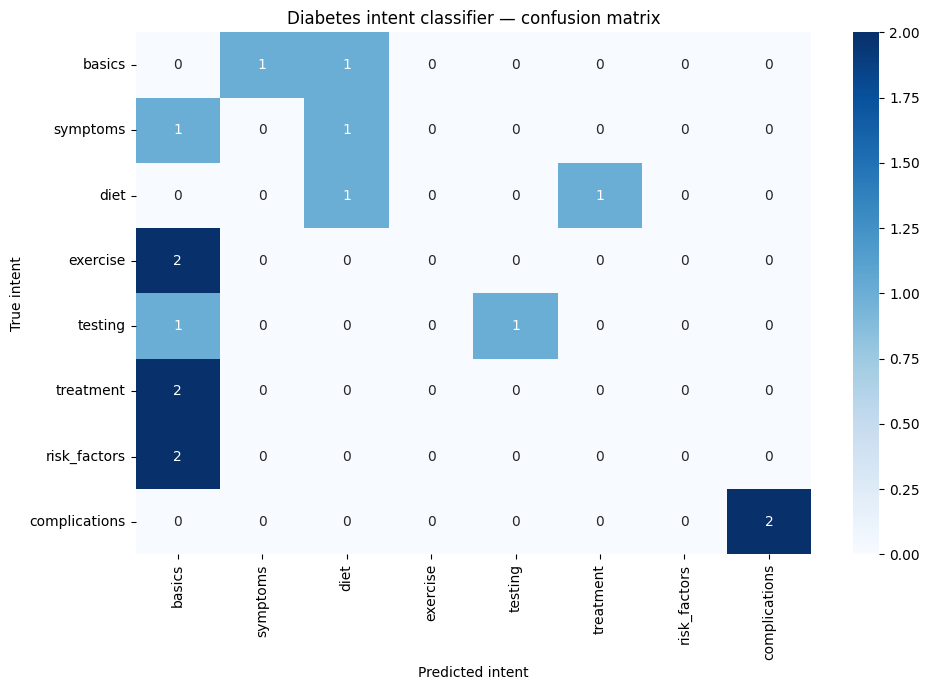

In [7]:
acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
metrics_df = pd.DataFrame({"Metric": ["Accuracy", "Weighted precision", "Weighted recall", "Weighted F1"],
                           "Value": [acc, prec, rec, f1]})
display(metrics_df.style.format({"Value":"{:.3f}"}))
print(classification_report(y_test, y_pred, zero_division=0))
labels = list(DATA[DOMAIN].keys())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"{DOMAIN.title()} intent classifier — confusion matrix")
plt.xlabel("Predicted intent"); plt.ylabel("True intent")
plt.tight_layout(); plt.show()

## 8. Knowledge base — one expert-reviewed-style educational entry per intent
Content is general information, not patient-specific diagnosis, treatment, or emergency triage. The responses encourage professional assessment when appropriate.

In [8]:
KNOWLEDGE_BASE = {
"diabetes": {
"basics": "Diabetes is a long-term condition involving higher-than-normal blood glucose. Insulin helps cells use glucose. Type 1 diabetes involves little or no insulin production, while type 2 commonly involves insulin resistance and sometimes reduced insulin production.",
"symptoms": "Possible diabetes symptoms include increased thirst, frequent urination, fatigue, blurred vision, and unexplained weight loss. Some people have no obvious symptoms. A healthcare professional can assess symptoms and arrange testing.",
"diet": "Balanced meals with vegetables, whole grains, legumes, adequate protein, and high-fiber foods can support glucose management. Sugary drinks and large portions of refined carbohydrates can raise glucose quickly. Individual meal plans vary; seek advice from a qualified clinician or dietitian.",
"exercise": "Regular movement such as walking, cycling, or suitable strength exercise can support glucose management. Start gradually when appropriate. People using insulin or glucose-lowering medicines should ask their care team about low-blood-sugar precautions around exercise.",
"testing": "Common diabetes tests include HbA1c (average glucose over roughly 2–3 months), fasting plasma glucose, and sometimes an oral glucose tolerance test. Home glucose meters and continuous glucose monitors help some people track glucose. Diagnosis requires appropriate professional testing.",
"treatment": "Diabetes management can include food choices, physical activity, monitoring, and prescribed medicines. People with type 1 diabetes need insulin. Treatment for type 2 diabetes is individualized and may include medicines such as metformin or insulin. Do not change medicines without your prescriber.",
"risk_factors": "Risk factors for type 2 diabetes can include family history, prediabetes, lower physical activity, certain age-related or metabolic factors, and excess body fat. Not everyone with these risk factors develops diabetes. Ask a clinician about appropriate screening.",
"complications": "Long-standing high glucose can contribute to eye, kidney, nerve, foot, and cardiovascular problems. Regular checkups, suitable glucose management, blood pressure and cholesterol care, and recommended screening can help reduce risks."},
"heart": {
"basics": "The heart pumps blood throughout the body. Cardiovascular health concerns the heart and blood vessels. Coronary artery disease occurs when plaque builds up in the arteries supplying the heart, potentially limiting blood flow.",
"symptoms": "Heart-related problems can cause chest discomfort, breathlessness, unusual fatigue, palpitations, or swelling, although symptoms vary. New or persistent symptoms deserve medical evaluation. Severe or sudden symptoms may be an emergency.",
"diet": "An eating pattern rich in vegetables, fruit, whole grains, legumes, nuts, and unsaturated fats can support heart health. Limiting excess sodium, highly processed foods, and saturated fats may help blood pressure and cholesterol. Individual needs vary.",
"exercise": "Regular physical activity such as walking, cycling, or other suitable aerobic exercise supports cardiovascular fitness. Build up gradually. Anyone with known heart disease, concerning symptoms, or exercise limitations should ask their clinician for personalized activity guidance.",
"testing": "Heart-health assessment may include blood pressure measurement, lipid tests, ECG, echocardiogram, or stress testing, depending on symptoms and risk. A clinician selects tests based on the individual situation.",
"treatment": "Heart condition management depends on diagnosis and may include lifestyle changes, prescribed medicines, cardiac rehabilitation, or procedures such as stenting when clinically indicated. Never start, stop, or change heart medication without medical advice.",
"risk_factors": "Cardiovascular risk factors include high blood pressure, high LDL cholesterol, smoking, diabetes, inactivity, and family history. Addressing modifiable factors and discussing preventive screening with a clinician may lower risk.",
"complications": "Cardiovascular disease can lead to heart attack, heart failure, certain rhythm problems, or stroke, depending on the condition. Preventive care and timely treatment matter; sudden chest pain or stroke signs require emergency services."}
}
assert all(intent in KNOWLEDGE_BASE[DOMAIN] for intent in DATA[DOMAIN])
display(pd.DataFrame([{"intent":k,"knowledge":v} for k,v in KNOWLEDGE_BASE[DOMAIN].items()]))

,intent,knowledge
0,basics,Diabetes is a long-term condition involving hi...
1,symptoms,Possible diabetes symptoms include increased t...
2,diet,"Balanced meals with vegetables, whole grains, ..."
3,exercise,"Regular movement such as walking, cycling, or ..."
4,testing,Common diabetes tests include HbA1c (average g...
5,treatment,"Diabetes management can include food choices, ..."
6,risk_factors,Risk factors for type 2 diabetes can include f...
7,complications,Long-standing high glucose can contribute to e...


## 9. Rule-based reasoning and integrated assistant
The assistant applies these explicit rules in priority order:

1. **Emergency escalation:** potentially urgent chest pain, stroke signs, severe breathing difficulty, unconsciousness, etc. → emergency response (before ML).
2. **Unsupported medical-domain query:** unrelated medical specialty → explain scope.
3. **Empty/non-question input:** request a valid question.
4. **Out-of-vocabulary / low relevance:** no matching TF–IDF terms → unsupported/clarification.
5. **Low-confidence handling:** weak predicted intent probability or small gap between leading classes → ask for rephrasing.
6. **Supported prediction:** retrieve intent-specific knowledge and display predicted intent and confidence.

Because the model is trained on a small, synthetic labelled corpus, its probabilities are **not calibrated medical confidence scores**.

In [9]:
EMERGENCY_PATTERNS = [
 r"\b(chest pain|crushing chest|severe chest|heart attack|stroke|face droop|facial droop|slurred speech|one.sided weakness|unconscious|passed out|not breathing|severe breathlessness|severe difficulty breathing|seizure)\b",
 r"\b(can't breathe|cannot breathe|trouble breathing suddenly|fainting with chest)\b"
]
# These terms intentionally target clearly off-topic healthcare topics, not common overlapping heart/diabetes topics.
OFF_TOPIC_PATTERNS = [
 r"\b(toothache|dental cavity|braces|wisdom tooth|root canal|acne|eczema|skin rash|broken bone|fracture|ear infection|earache|migraine|pregnancy|appendicitis)\b"
]
EMERGENCY_MESSAGE = ("🚨 **Possible medical emergency.** Call your local emergency number now "
                     "(112 in India) or seek emergency medical care immediately. "
                     "Do not rely on this chatbot or delay care. If safe, have someone stay with you.")

# Use genuine regex word boundaries. Strings above are stored with double backslashes for notebook generation.

def answer_query(query, min_probability=0.25, min_margin=0.035):
    text = str(query).strip()
    if not text:
        return {"rule":"empty_input", "intent":None, "confidence":None,
                "response":"Please enter a question about " + DOMAIN + " care."}
    if any(re.search(p, text.lower(), re.I) for p in EMERGENCY_PATTERNS):
        return {"rule":"emergency", "intent":None, "confidence":None, "response":EMERGENCY_MESSAGE}
    if any(re.search(p, text.lower(), re.I) for p in OFF_TOPIC_PATTERNS):
        return {"rule":"unsupported", "intent":None, "confidence":None,
                "response":f"This assistant covers {DOMAIN} information only. For other health concerns, consult a healthcare professional."}
    cleaned = preprocess(text)
    if not cleaned:
        return {"rule":"low_confidence", "intent":None, "confidence":None,
                "response":f"Please rephrase your question about {DOMAIN} with more detail."}
    vector = model.named_steps["tfidf"].transform([cleaned])
    if vector.nnz == 0:
        return {"rule":"unsupported", "intent":None, "confidence":None,
                "response":f"I cannot identify a supported {DOMAIN} topic. Ask about symptoms, diet, exercise, testing, treatment, risk, or complications."}
    probabilities = model.named_steps["classifier"].predict_proba(vector)[0]
    order = np.argsort(probabilities)[::-1]
    best_index = order[0]
    confidence = float(probabilities[best_index])
    margin = confidence - float(probabilities[order[1]])
    intent = str(model.classes_[best_index])
    if confidence < min_probability or margin < min_margin:
        return {"rule":"low_confidence", "intent":intent, "confidence":confidence,
                "response":f"I'm not certain which {DOMAIN} topic you mean. Could you rephrase and mention symptoms, diet, exercise, testing, treatment, risks, or complications?"}
    return {"rule":"knowledge_retrieval", "intent":intent, "confidence":confidence,
            "response":KNOWLEDGE_BASE[DOMAIN][intent] + "\n\n*Educational information only; not a diagnosis or individual treatment advice.*"}

def print_answer(question):
    result = answer_query(question)
    confidence_text = "N/A" if result["confidence"] is None else f'{result["confidence"]:.2%}'
    display(Markdown(f"**Question:** {question}\n\n**Rule:** `{result['rule']}` | **Intent:** `{result['intent']}` | **Model score:** {confidence_text}\n\n{result['response']}"))
    return result

print_answer("What can I do to improve my " + ("blood sugar?" if DOMAIN=="diabetes" else "heart health through exercise?"))

**Question:** What can I do to improve my blood sugar?

**Rule:** `low_confidence` | **Intent:** `diet` | **Model score:** 24.18%

I'm not certain which diabetes topic you mean. Could you rephrase and mention symptoms, diet, exercise, testing, treatment, risks, or complications?

{'rule': 'low_confidence',
 'intent': 'diet',
 'confidence': 0.24184829090455465,
 'response': "I'm not certain which diabetes topic you mean. Could you rephrase and mention symptoms, diet, exercise, testing, treatment, risks, or complications?"}

## 10. Required testing (all intent classes + paraphrase + unsupported + low-confidence + emergency)


In [10]:
TEST_QUERIES = {
"diabetes": {
 "basics":"Explain what diabetes means", "symptoms":"What signs suggest diabetes?",
 "diet":"What food choices help glucose?", "exercise":"Is walking useful with diabetes?",
 "testing":"What does HbA1c check?", "treatment":"How do doctors treat diabetes?",
 "risk_factors":"Does family history raise diabetes risk?", "complications":"Can diabetes harm the kidneys?",
 "paraphrase":"Why do I need to pee so often and feel thirsty?",
 "unsupported":"Can braces fix crooked teeth?", "low_confidence":"Could you give information about things?",
 "emergency":"I have crushing chest pain and cannot breathe"
},
"heart": {
 "basics":"What does the heart do?", "symptoms":"What are warning signs of heart problems?",
 "diet":"Which foods support cardiovascular health?", "exercise":"Is cycling useful for the heart?",
 "testing":"What is an ECG used for?", "treatment":"How is coronary artery disease managed?",
 "risk_factors":"Does high LDL increase heart disease risk?", "complications":"Can cardiovascular disease cause stroke?",
 "paraphrase":"What should I eat to keep my ticker healthy?",
 "unsupported":"Do dental braces straighten teeth?", "low_confidence":"Could you give information about things?",
 "emergency":"Sudden slurred speech and one-sided weakness"
}}
results=[]
for test_type, question in TEST_QUERIES[DOMAIN].items():
    # Ambiguous query: increase the cutoff only for this test to show low-confidence handling.
    output = answer_query(question, min_probability=0.99) if test_type=="low_confidence" else answer_query(question)
    results.append({"test_case":test_type,"query":question,"rule":output["rule"],"predicted_intent":output["intent"],
                    "response":output["response"]})
test_df = pd.DataFrame(results)
display(test_df)
print("Emergency rule triggered:", test_df.loc[test_df.test_case=="emergency", "rule"].iloc[0]=="emergency")
print("Unsupported rule triggered:", test_df.loc[test_df.test_case=="unsupported", "rule"].iloc[0]=="unsupported")
print("Low-confidence rule triggered:", test_df.loc[test_df.test_case=="low_confidence", "rule"].iloc[0]=="low_confidence")

,test_case,query,rule,predicted_intent,response
0,basics,Explain what diabetes means,low_confidence,basics,I'm not certain which diabetes topic you mean....
1,symptoms,What signs suggest diabetes?,knowledge_retrieval,symptoms,Possible diabetes symptoms include increased t...
2,diet,What food choices help glucose?,low_confidence,diet,I'm not certain which diabetes topic you mean....
3,exercise,Is walking useful with diabetes?,low_confidence,exercise,I'm not certain which diabetes topic you mean....
4,testing,What does HbA1c check?,low_confidence,testing,I'm not certain which diabetes topic you mean....
5,treatment,How do doctors treat diabetes?,low_confidence,treatment,I'm not certain which diabetes topic you mean....
6,risk_factors,Does family history raise diabetes risk?,knowledge_retrieval,risk_factors,Risk factors for type 2 diabetes can include f...
7,complications,Can diabetes harm the kidneys?,low_confidence,basics,I'm not certain which diabetes topic you mean....
8,paraphrase,Why do I need to pee so often and feel thirsty?,unsupported,None,I cannot identify a supported diabetes topic. ...
9,unsupported,Can braces fix crooked teeth?,unsupported,None,This assistant covers diabetes information onl...


Emergency rule triggered: True
Unsupported rule triggered: True
Low-confidence rule triggered: False


## 11. Interactive Google Colab interface — multiple queries
Enter **one query per line**, press **Get responses**, and review all responses below. Works with Colab's widget support.

In [11]:
query_box = widgets.Textarea(
    value=("What is diabetes?\nHow does walking help glucose?" if DOMAIN=="diabetes" else
           "What is heart health?\nHow does walking help the heart?"),
    placeholder="One question per line...", description="Questions:",
    layout=widgets.Layout(width="95%", height="120px"), style={"description_width":"initial"})
ask_button = widgets.Button(description="Get responses", button_style="success", icon="comment")
clear_button = widgets.Button(description="Clear", icon="trash")
output_box = widgets.Output(layout=widgets.Layout(border="1px solid #ddd", padding="10px"))

def on_ask(_):
    with output_box:
        clear_output(wait=True)
        questions = [q.strip() for q in query_box.value.splitlines() if q.strip()]
        if not questions:
            display(Markdown("Enter at least one question.")); return
        for idx, q in enumerate(questions, start=1):
            display(Markdown(f"### Question {idx}"))
            print_answer(q)

def on_clear(_):
    query_box.value = ""
    with output_box: clear_output()
ask_button.on_click(on_ask)
clear_button.on_click(on_clear)
display(Markdown(f"### Interactive {DOMAIN.title()} Information Assistant"))
display(query_box, widgets.HBox([ask_button, clear_button]), output_box)

### Interactive Diabetes Information Assistant

Textarea(value='What is diabetes?\nHow does walking help glucose?', description='Questions:', layout=Layout(he…

Output(layout=Layout(border='1px solid #ddd', padding='10px'))

## 12. Export the labelled corpus and evaluation results (optional)


In [12]:
df.to_csv(f"{DOMAIN}_labelled_corpus.csv", index=False)
metrics_df.to_csv(f"{DOMAIN}_evaluation_metrics.csv", index=False)
test_df.to_csv(f"{DOMAIN}_test_cases.csv", index=False)
relation_df.to_csv(f"{DOMAIN}_concept_relationships.csv", index=False)
print("Saved 4 CSV files for", DOMAIN)

Saved 4 CSV files for diabetes


### Assignment requirement coverage
| Assignment item | Notebook section |
|---|---|
| ≥40 labelled queries, ≥5 intents | 3 — 64 queries, 8 intents |
| ≥4 taxonomy categories, ≥2 subcategories each | 2 |
| ≥8 concepts, ≥10 relationships | 4 |
| Lowercase, tokenize, stopwords, lemmatize | 5 |
| TF-IDF + ML classifier | 6 |
| Accuracy, precision, recall, F1, confusion matrix | 7 |
| Domain knowledge base | 8 |
| ≥5 reasoning rules | 9 |
| Integrated assistant | 9 |
| Colab interactive multiple-query UI | 11 |
| 5 types of required testing | 10 |

**Notes:** Small illustrative training data can yield unstable test metrics. This is a classroom demonstration, not a clinically validated AI system. The emergency keyword detector is illustrative and cannot guarantee detection of all emergencies.